# Alexander vs Perturb-Seqr (all libraries)

## Setup

In [1]:
import gzip
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

import perturbseqr as ps
from maayanlab_bioinformatics.parse.gmt import gmt_read_dict, parse_gene_unweighted
from maayanlab_bioinformatics.harmonization import ncbi_genes_fetch, ncbi_genes_lookup

GMT_ROOT = Path("/Users/johngardner_mountsinai/work/PerturbSeqr/db/data")
GENE_SETS = Path("gene_sets")
MUTATIONS = ["R239H", "R239C", "R79C", "R79H", "R239G"]
NCBI_CACHE = Path.home() / ".cache" / "ncbi_genes"
NCBI_CACHE.mkdir(parents=True, exist_ok=True)

## Perturb-Seqr stats

In [ ]:
perturbseqr_sets = {}
for path in sorted(GMT_ROOT.glob("*_perturbation/*.gmt.gz")):
    with gzip.open(path, "rt") as fh:
        perturbseqr_sets.update(gmt_read_dict(fh, parse_gene=parse_gene_unweighted))

perturbseqr_bg = {g.upper() for genes in perturbseqr_sets.values() for g in genes}
sizes = pd.Series([len(g) for g in perturbseqr_sets.values()])

print(f"gene sets:    {len(perturbseqr_sets):,}")
print(f"unique genes: {len(perturbseqr_bg):,}")
print(f"set size:     median={sizes.median():.0f}, range=[{sizes.min()}, {sizes.max()}]")

gene sets:    426,911
unique genes: 22,221
set size:     median=246, range=[1, 11348]


## Load Alexander gene sets

In [ ]:
def load(mut, direction):
    return {l.strip().upper() for l in (GENE_SETS / f"{mut}_{direction}.txt").read_text().splitlines() if l.strip()}

per_mut = {m: (load(m, "up"), load(m, "down")) for m in MUTATIONS}
alex_genes = set().union(*(up | dn for up, dn in per_mut.values()))
print(f"unique alexander genes: {len(alex_genes)}")

unique alexander genes: 362


## Venn — Alexander vs Perturb-Seqr (raw)

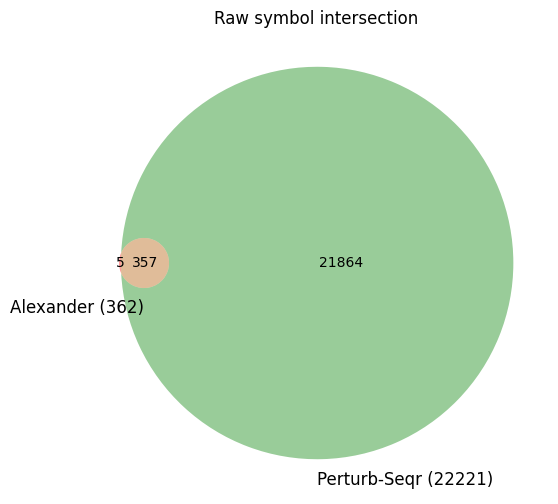

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
venn2([alex_genes, perturbseqr_bg],
      set_labels=(f"Alexander ({len(alex_genes)})", f"Perturb-Seqr ({len(perturbseqr_bg)})"), ax=ax)
ax.set_title("Raw symbol intersection")
plt.show()

## Per-mutation paired enrichment vs all libraries

In [ ]:
results = {}
for m, (up, dn) in per_mut.items():
    df = ps.enrich_pair(
        up=sorted(up), down=sorted(dn),
        top=50, sort_by="pvalue_reverse", pvalue_le=0.05,
    )
    results[m] = df
    print(f"{m}: up={len(up)}, down={len(dn)}, results={len(df)}")

R239H: up=61, down=123, results=26
R239C: up=34, down=67, results=0
R79C: up=63, down=70, results=2
R79H: up=57, down=75, results=0
R239G: up=54, down=90, results=0


### R239H

In [ ]:
results["R239H"][["term", "library_name", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(results["R239H"]) else "No enriched terms" 

,term,library_name,nGeneIds,adjPvalueMimic,adjPvalueReverse,mimickerOverlap,reverserOverlap
0,JAK2::colon cancer cell vorinostat-resistant H...,Perturb Atlas Human,100,1,0.000837,1,13
1,JAK2::colon cancer cell vorinostat-resistant H...,Perturb Atlas Human,100,1,0.000837,1,13
2,RELA::::ES-derived mesenchymal stem cells:::::...,Perturb Atlas Human,98,1,0.00258,1,12
3,RELA::::ES-derived mesenchymal stem cells:::::...,Perturb Atlas Human,99,1,0.00258,1,12
4,SEM1::RPE1::::day7::::KD::CRISPRi::P1P2::essen...,Replogle et al.,67,1,0.045151,0,8
5,SEM1::RPE1::::day7::::KD::CRISPRi::P1P2::essen...,Replogle et al.,25,1,0.045151,0,8
6,ALDOA::RPE1::::day7::::KD::CRISPRi::P1P2::esse...,Replogle et al.,80,1,0.045151,0,8
7,ALDOA::RPE1::::day7::::KD::CRISPRi::P1P2::esse...,Replogle et al.,21,1,0.045151,0,8
8,ZNHIT3::RPE1::::day7::::KD::CRISPRi::P1P2::ess...,Replogle et al.,64,1,0.045151,0,8
9,ZNHIT3::RPE1::::day7::::KD::CRISPRi::P1P2::ess...,Replogle et al.,38,1,0.045151,0,8


### R239C

In [ ]:
results["R239C"][["term", "library_name", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(results["R239C"]) else "No enriched terms" 

'No enriched terms'

### R79C

In [ ]:
results["R79C"][["term", "library_name", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(results["R79C"]) else "No enriched terms" 

,term,library_name,nGeneIds,adjPvalueMimic,adjPvalueReverse,mimickerOverlap,reverserOverlap
0,XPO6::breast cancer cell MCF-7::::::::KD::::S...,Perturb Atlas Human,97,0.010852,1,10,0
1,XPO6::breast cancer cell MCF-7::::::::KD::::S...,Perturb Atlas Human,99,0.010852,1,10,0


### R79H

In [ ]:
results["R79H"][["term", "library_name", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(results["R79H"]) else "No enriched terms" 

'No enriched terms'

### R239G

In [ ]:
results["R239G"][["term", "library_name", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(results["R239G"]) else "No enriched terms" 

'No enriched terms'

## Union paired enrichment

In [ ]:
union_up   = set().union(*(up for up, _ in per_mut.values()))
union_down = set().union(*(dn for _, dn in per_mut.values()))
conflicting = union_up_raw & union_down_raw

print(f"union up:    {len(union_up)}")
print(f"union down:  {len(union_down)}")
print(f"conflicting: {len(conflicting)} -> {sorted(conflicting) if conflicting else '[]'}")

union up:    133
union down:  252
conflicting: 23 -> ['AADAT', 'ABCA2', 'AMIGO2', 'APOA1', 'ASS1', 'C16ORF87', 'CEMIP', 'CXCL14', 'DNAL1', 'DUS1L', 'FERRY3', 'HSP90AA2P', 'ITIH2', 'KRT75', 'LMBRD2', 'MAPK12', 'MYH10', 'POLR2M', 'PUDP', 'RAC2', 'SELENBP1', 'WASF3', 'ZMAT5']


In [ ]:
df_union = ps.enrich_pair(
    up=union_up, down=union_down,
    top=50, sort_by="pvalue_reverse", pvalue_le=0.05,
)
df_union[["term", "library_name", "nGeneIds", "adjPvalueMimic", "adjPvalueReverse", "mimickerOverlap", "reverserOverlap"]] if len(df_union) else "No enriched terms" 

,term,library_name,nGeneIds,adjPvalueMimic,adjPvalueReverse,mimickerOverlap,reverserOverlap
0,JAK2::colon cancer cell vorinostat-resistant H...,Perturb Atlas Human,100,1,0.036908,4,16
1,JAK2::colon cancer cell vorinostat-resistant H...,Perturb Atlas Human,100,1,0.036908,4,16
2,Milnacipran::U2OS::::24h::1uM::NSN:MC-40-IP75 up,NIBR DRUG-seq,16,0.000211,1,10,4
3,Milnacipran::U2OS::::24h::1uM::NSN:MC-40-IP75 ...,NIBR DRUG-seq,25,0.000211,1,10,4


## Caffeine check

Search for any Perturb-Seqr signature whose term contains "caffeine" across all libraries,
then filter the union enrichment for reverser hits matching caffeine.

In [ ]:
caffeine_terms = ps.term_search("caffeine", top=200)
print(f"Perturb-Seqr signatures containing 'caffeine': {len(caffeine_terms)}")
caffeine_terms

Perturb-Seqr signatures containing 'caffeine': 37


,term,id,library_name,nGeneIds
0,8-(3-Chlorostyryl)caffeine::U2OS::::24h::0.1uM...,8800842b-a519-4c28-a090-66fe7079670b,NIBR DRUG-seq,10
1,Caffeine::A549::::24h::1uM up,57f3cb8a-098d-486e-a0bd-e2ba16758b4f,Ginkgo Bioworks,341
2,Caffeine::A549::::24h::1uM down,dd38069b-a032-49d1-b2be-4b33a131b798,Ginkgo Bioworks,360
3,caffeine::A549::::24H::10uM::CPC015::G24 up,6c370ce6-2239-46fa-9c27-50c7661bcce6,LINCS L1000 CP,246
4,8-(3-Chlorostyryl)caffeine::A549::::24h::1uM up,8f4626c6-0de9-4f7a-b51e-d8ca7994bdae,Ginkgo Bioworks,350
5,caffeine::A375::::24H::0.01uM::REP.B012::L12 down,7f8ad082-bec5-4beb-8db2-cca3f8de0129,LINCS L1000 CP,247
6,Caffeine::U2OS::::24h::0.1uM::NSN:AD-83-MW95 up,b88fdefd-b967-449b-a8eb-3ce24205cded,NIBR DRUG-seq,6
7,8-(3-Chlorostyryl)caffeine::U2OS::::24h::10uM:...,14d5328b-22e2-4782-a8a7-6f1845efd341,NIBR DRUG-seq,5
8,8-(3-Chlorostyryl)caffeine::U2OS::::24h::0.1uM...,29b3ff21-ef07-40cf-bff0-7ef22af755db,NIBR DRUG-seq,22
9,8-(3-Chlorostyryl)caffeine::A549::::24h::0.1uM...,9cbc7037-ca27-42c0-8bba-14a0d8a86f84,Ginkgo Bioworks,404


In [ ]:
caffeine_reversers = df_union[df_union["term"].str.contains("caffeine", case=False, na=False)]
caffeine_reversers if len(caffeine_reversers) else "No caffeine reversers in the union enrichment results."

'No caffeine reversers in the union enrichment results.'